In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv(r"C:\Users\janan\OneDrive\Desktop\EDA datasets\StudentsPerformance.csv")

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
print (df.shape)

(1000, 8)


In [5]:
print(df.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [6]:
print(df.duplicated().sum())

0


In [7]:
df["gender"] = df["gender"].str.strip().str.lower()

df["race/ethnicity"] = df["race/ethnicity"].str.strip().str.lower()

df["parental level of education"] = df["parental level of education"].str.strip().str.lower()

df["lunch"] = df["lunch"].str.strip().str.lower()

df["test preparation course"] = df["test preparation course"].str.strip().str.lower()

In [8]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group b,bachelor's degree,standard,none,72,72,74
1,female,group c,some college,standard,completed,69,90,88
2,female,group b,master's degree,standard,none,90,95,93
3,male,group a,associate's degree,free/reduced,none,47,57,44
4,male,group c,some college,standard,none,76,78,75


In [9]:
scores = ["math score", "reading score", "writing score"]

print("Mean:")
print(df[scores].mean())

print("\nMedian:")
print(df[scores].median())

print("\nStandard Deviation:")
print(df[scores].std())

Mean:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

Median:
math score       66.0
reading score    70.0
writing score    69.0
dtype: float64

Standard Deviation:
math score       15.163080
reading score    14.600192
writing score    15.195657
dtype: float64


In [10]:
print("Minimum Marks:")
print(df[scores].min())

print("\nMaximum Marks:")
print(df[scores].max())

print("\nQuartiles:")
print(df[scores].quantile([0.25, 0.50, 0.75]))

Minimum Marks:
math score        0
reading score    17
writing score    10
dtype: int64

Maximum Marks:
math score       100
reading score    100
writing score    100
dtype: int64

Quartiles:
      math score  reading score  writing score
0.25        57.0           59.0          57.75
0.50        66.0           70.0          69.00
0.75        77.0           79.0          79.00


In [11]:
df["Total Marks"] = df["math score"] + df["reading score"] + df["writing score"]

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Marks
0,female,group b,bachelor's degree,standard,none,72,72,74,218
1,female,group c,some college,standard,completed,69,90,88,247
2,female,group b,master's degree,standard,none,90,95,93,278
3,male,group a,associate's degree,free/reduced,none,47,57,44,148
4,male,group c,some college,standard,none,76,78,75,229


In [12]:
df["Percentage"] = (df["Total Marks"] / 300) * 100

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Marks,Percentage
0,female,group b,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group c,some college,standard,completed,69,90,88,247,82.333333
2,female,group b,master's degree,standard,none,90,95,93,278,92.666667
3,male,group a,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group c,some college,standard,none,76,78,75,229,76.333333


In [13]:
for col in scores:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print("\nSubject:", col)
    print("IQR:", IQR)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))
    print("Outlier Values:")
    print(outliers[col].tolist())


Subject: math score
IQR: 20.0
Lower Limit: 27.0
Upper Limit: 107.0
Number of Outliers: 8
Outlier Values:
[18, 0, 22, 24, 26, 19, 23, 8]

Subject: reading score
IQR: 20.0
Lower Limit: 29.0
Upper Limit: 109.0
Number of Outliers: 6
Outlier Values:
[17, 26, 28, 23, 24, 24]

Subject: writing score
IQR: 21.25
Lower Limit: 25.875
Upper Limit: 110.875
Number of Outliers: 5
Outlier Values:
[10, 22, 19, 15, 23]


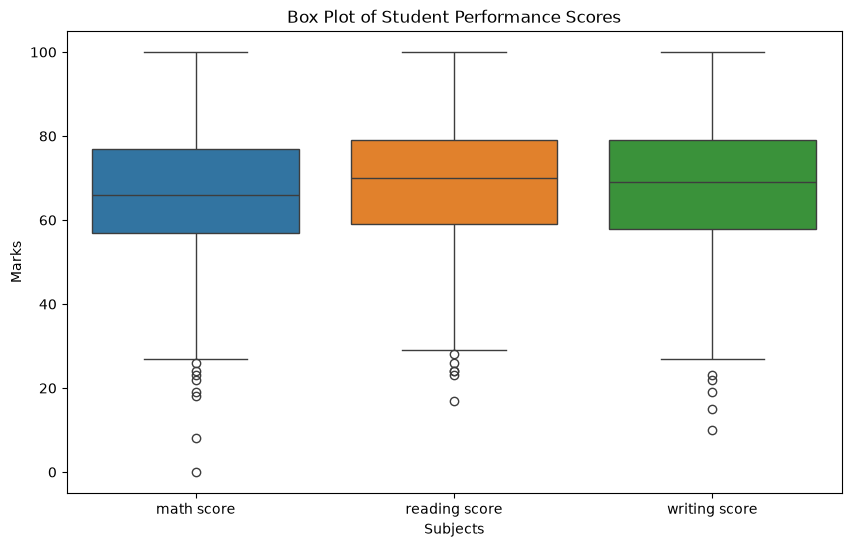

In [14]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[scores])

plt.title("Box Plot of Student Performance Scores")
plt.xlabel("Subjects")
plt.ylabel("Marks")
plt.show()

In [15]:
df.to_csv("Cleaned StudentsPerformance.csv")